In [1]:
%pip install pandas numpy scikit-learn matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
print("Current working directory:", os.getcwd())

print("\nCSV files available:")

for file in os.listdir():
    if file.lower().endswith(".csv"):
        print(file)

Current working directory: C:\Users\soham\python for ai

CSV files available:
healthcare_dataset.csv
Phishing_Email.csv


In [3]:
df = pd.read_csv("Phishing_Email.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (18650, 3)


,Unnamed: 0,Email Text,Email Type
0,0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,1,the other side of * galicismos * * galicismo *...,Safe Email
2,2,re : equistar deal tickets are you still avail...,Safe Email
3,3,\nHello I am your hot lil horny toy.\n I am...,Phishing Email
4,4,software at incredibly low prices ( 86 % lower...,Phishing Email


In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst five records:")
display(df.head())

Column names:
['Unnamed: 0', 'Email Text', 'Email Type']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18650 entries, 0 to 18649
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  18650 non-null  int64 
 1   Email Text  18634 non-null  object
 2   Email Type  18650 non-null  object
dtypes: int64(1), object(2)
memory usage: 437.2+ KB

Missing values:
Unnamed: 0     0
Email Text    16
Email Type     0
dtype: int64

First five records:


,Unnamed: 0,Email Text,Email Type
0,0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,1,the other side of * galicismos * * galicismo *...,Safe Email
2,2,re : equistar deal tickets are you still avail...,Safe Email
3,3,\nHello I am your hot lil horny toy.\n I am...,Phishing Email
4,4,software at incredibly low prices ( 86 % lower...,Phishing Email


Email Type
Safe Email        11322
Phishing Email     7328
Name: count, dtype: int64


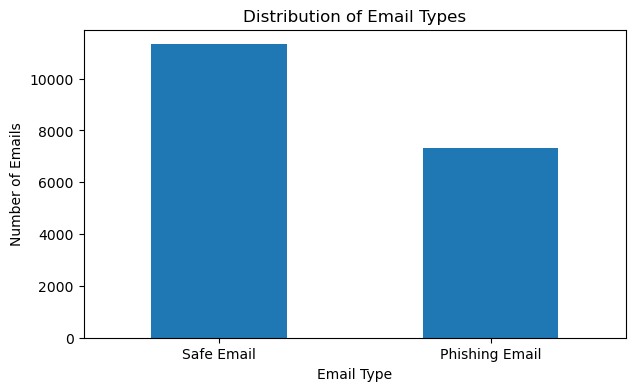

In [5]:
print(df["Email Type"].value_counts(dropna=False))

df["Email Type"].value_counts().plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Distribution of Email Types")
plt.xlabel("Email Type")
plt.ylabel("Number of Emails")
plt.xticks(rotation=0)
plt.show()

In [6]:
# Find the text and label columns
column_map = {
    str(col).strip().lower(): col
    for col in df.columns
}

possible_text_columns = [
    "email text",
    "email_text",
    "text",
    "email",
    "message"
]

possible_label_columns = [
    "email type",
    "email_type",
    "label",
    "type",
    "class"
]

text_col = next(
    (column_map[c] for c in possible_text_columns
     if c in column_map),
    None
)

label_col = next(
    (column_map[c] for c in possible_label_columns
     if c in column_map),
    None
)

if text_col is None or label_col is None:
    raise ValueError(
        f"Could not identify text and label columns. "
        f"Available columns: {df.columns.tolist()}"
    )

print("Text column:", text_col)
print("Label column:", label_col)

# Keep only the required columns
data = df[[text_col, label_col]].copy()

data.columns = ["email_text", "label"]

# Remove missing values
data = data.dropna(subset=["email_text", "label"])

# Convert email text to strings and remove blank records
data["email_text"] = data["email_text"].astype(str).str.strip()

data = data[data["email_text"] != ""]

# Normalize labels
data["label"] = (
    data["label"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Map common label names
label_mapping = {
    "safe email": 0,
    "safe": 0,
    "legitimate": 0,
    "legitimate email": 0,
    "ham": 0,
    "phishing email": 1,
    "phishing": 1,
    "phishing email ": 1,
    "spam": 1,
    "1": 1,
    "0": 0
}

data["label"] = data["label"].map(label_mapping)

# Remove labels that could not be mapped
data = data.dropna(subset=["label"])

data["label"] = data["label"].astype(int)

print("Cleaned dataset shape:", data.shape)

print("\nLabel distribution:")
print(data["label"].value_counts())

display(data.head())

Text column: Email Text
Label column: Email Type
Cleaned dataset shape: (18631, 2)

Label distribution:
label
0    11322
1     7309
Name: count, dtype: int64


,email_text,label
0,"re : 6 . 1100 , disc : uniformitarianism , re ...",0
1,the other side of * galicismos * * galicismo *...,0
2,re : equistar deal tickets are you still avail...,0
3,Hello I am your hot lil horny toy.\n I am t...,1
4,software at incredibly low prices ( 86 % lower...,1


In [7]:
before = len(data)

data = data.drop_duplicates(
    subset=["email_text", "label"]
).reset_index(drop=True)

after = len(data)

print("Records before duplicate removal:", before)
print("Records after duplicate removal:", after)
print("Duplicates removed:", before - after)

Records before duplicate removal: 18631
Records after duplicate removal: 17523
Duplicates removed: 1108


In [8]:
X = data["email_text"]
y = data["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Training samples: 14018
Testing samples: 3505

Training label distribution:
label
0    8783
1    5235
Name: count, dtype: int64

Testing label distribution:
label
0    2196
1    1309
Name: count, dtype: int64


In [9]:
model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            ngram_range=(1, 2),
            max_features=50000,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

print("Training model...")

model.fit(X_train, y_train)

print("Training completed successfully!")

Training model...
Training completed successfully!


In [10]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print("Number of test predictions:", len(y_pred))

Predictions generated successfully!
Number of test predictions: 3505


In [11]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print("=" * 45)
print("PHISHING EMAIL DETECTION RESULTS")
print("=" * 45)

print(f"Accuracy : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall   : {recall:.4f} ({recall * 100:.2f}%)")
print(f"F1-score : {f1:.4f} ({f1 * 100:.2f}%)")

print("\nDetailed Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Safe Email", "Phishing Email"],
        zero_division=0
    )
)

PHISHING EMAIL DETECTION RESULTS
Accuracy : 0.9820 (98.20%)
Precision: 0.9663 (96.63%)
Recall   : 0.9862 (98.62%)
F1-score : 0.9762 (97.62%)

Detailed Classification Report:

                precision    recall  f1-score   support

    Safe Email       0.99      0.98      0.99      2196
Phishing Email       0.97      0.99      0.98      1309

      accuracy                           0.98      3505
     macro avg       0.98      0.98      0.98      3505
  weighted avg       0.98      0.98      0.98      3505



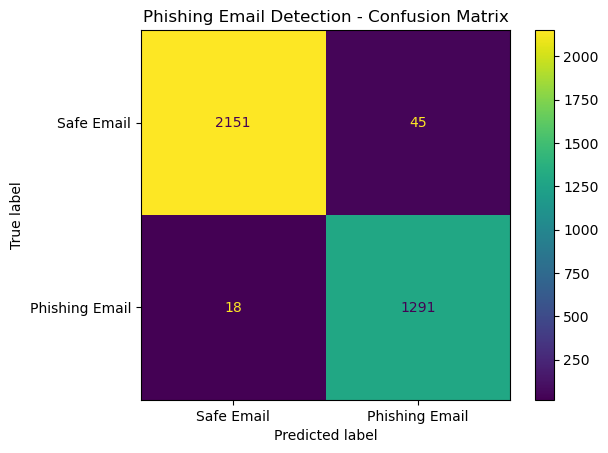

In [12]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Safe Email", "Phishing Email"]
)

disp.plot(values_format="d")

plt.title("Phishing Email Detection - Confusion Matrix")
plt.show()

In [14]:
def predict_email(email_text):
    prediction = int(model.predict([email_text])[0])

    probabilities = model.predict_proba([email_text])[0]
    classes = model.named_steps["classifier"].classes_

    probability_map = dict(zip(classes, probabilities))

    phishing_probability = float(
        probability_map.get(1, 0.0)
    )

    safe_probability = float(
        probability_map.get(0, 0.0)
    )

    result = (
        "PHISHING EMAIL"
        if prediction == 1
        else "SAFE EMAIL"
    )

    print("=" * 50)
    print("EMAIL ANALYSIS RESULT")
    print("=" * 50)

    print("\nEmail:")
    print(email_text)

    print("\nPrediction:", result)

    print(
        f"Phishing model score: "
        f"{phishing_probability * 100:.2f}%"
    )

    print(
        f"Safe model score: "
        f"{safe_probability * 100:.2f}%"
    )

    print("\nImportant:")
    print(
        "These are model scores, not verified probabilities "
        "of whether an email is genuinely malicious."
    )

    return {
        "prediction": result,
        "phishing_score": phishing_probability,
        "safe_score": safe_probability
    }

In [15]:
test_email_1 = """
URGENT: Your bank account will be suspended today.

Verify your account immediately to avoid permanent suspension.
Click the link below and enter your login credentials.
Failure to act immediately may result in account termination.
"""

result_1 = predict_email(test_email_1)

EMAIL ANALYSIS RESULT

Email:

URGENT: Your bank account will be suspended today.

Verify your account immediately to avoid permanent suspension.
Click the link below and enter your login credentials.
Failure to act immediately may result in account termination.


Prediction: PHISHING EMAIL
Phishing model score: 96.28%
Safe model score: 3.72%

Important:
These are model scores, not verified probabilities of whether an email is genuinely malicious.


In [16]:
test_email_1 = """
URGENT: Your bank account will be suspended today.

Verify your account immediately to avoid permanent suspension.
Click the link below and enter your login credentials.
Failure to act immediately may result in account termination.
"""

result_1 = predict_email(test_email_1)

EMAIL ANALYSIS RESULT

Email:

URGENT: Your bank account will be suspended today.

Verify your account immediately to avoid permanent suspension.
Click the link below and enter your login credentials.
Failure to act immediately may result in account termination.


Prediction: PHISHING EMAIL
Phishing model score: 96.28%
Safe model score: 3.72%

Important:
These are model scores, not verified probabilities of whether an email is genuinely malicious.


In [17]:
test_email_2 = """
Hi team,

Please find the meeting notes attached.
Our next project meeting is scheduled for Tuesday at 10 AM.
Let me know if you have any questions.

Regards,
Project Coordinator
"""

result_2 = predict_email(test_email_2)

EMAIL ANALYSIS RESULT

Email:

Hi team,

Please find the meeting notes attached.
Our next project meeting is scheduled for Tuesday at 10 AM.
Let me know if you have any questions.

Regards,
Project Coordinator


Prediction: SAFE EMAIL
Phishing model score: 3.79%
Safe model score: 96.21%

Important:
These are model scores, not verified probabilities of whether an email is genuinely malicious.


In [18]:
test_email_3 = """
Congratulations! You have won a cash prize.

Claim your reward immediately by submitting your personal details
and banking information through the link provided below.
"""

result_3 = predict_email(test_email_3)

EMAIL ANALYSIS RESULT

Email:

Congratulations! You have won a cash prize.

Claim your reward immediately by submitting your personal details
and banking information through the link provided below.


Prediction: PHISHING EMAIL
Phishing model score: 90.47%
Safe model score: 9.53%

Important:
These are model scores, not verified probabilities of whether an email is genuinely malicious.


In [19]:
model_filename = "phishing_email_model.joblib"

joblib.dump(model, model_filename)

print("Model saved successfully!")
print("File:", model_filename)

Model saved successfully!
File: phishing_email_model.joblib


In [20]:
loaded_model = joblib.load(
    "phishing_email_model.joblib"
)

sample_email = """
Your account has been locked.
Click the link immediately to verify your password.
"""

prediction = loaded_model.predict([sample_email])[0]

print(
    "Prediction:",
    "PHISHING EMAIL" if prediction == 1 else "SAFE EMAIL"
)

Prediction: PHISHING EMAIL
